**Insurance Charges Analysis**

**Project Scenario **

You are a Junior Data Analyst at a health insurance company. The company has provided you with a dataset of customers’ demographic and health information along with their medical insurance charges.
Your task is to:
- Clean and prepare the dataset,
- Explore and analyse relationships between features and insurance charges,
- Create meaningful visualisations using Pandas, Matplotlib, and Seaborn,
- Summarise your findings and present them to your manager.

Dataset Overview
The dataset contains the following key columns:
- age → Age of the insured person.
- sex → Gender of the insured person (male, female).
- bmi → Body Mass Index (an indicator of body fat based on height and weight).
- children → Number of children/dependents covered by the insurance.
 - smoker → Whether the person is a smoker (yes, no).
- region → Residential region of the insured (northwest, southeast, etc.).
 - charges → Medical insurance cost billed to the individual.

Business Context:
The company wants to identify which factors influence insurance charges the most (e.g.,  age, BMI, smoking status).
These insights will help in pricing policies and advising  customers.


**Analyst:** Paul O. Bankole, Junior Data Analyst  
**Aim:** identify which customer factors drive medical insurance charges, to support pricing and customer advice.

**Project Steps**

**Step:1 Import & Inspect the Data**

Instructions:

Import Pandas.

*   Load insurance.csv into a DataFrame named df.
*   Use head() to display the first few rows.
*   Use info() to check data types and missing values.
*   Use describe() to see summary statistics.





In [1]:
# Import libraries and load the dataset
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')

# Find the data: works from the repo (data/ folder) or in Colab (file uploaded next to the notebook)
candidates = ['../data/insurance.csv', 'data/insurance.csv', 'insurance.csv', 'insurance_2.csv']
DATA_FILE = next(p for p in candidates if os.path.exists(p))
DATA_DIR = os.path.dirname(DATA_FILE)
df = pd.read_csv(DATA_FILE)
print(f"Loaded {DATA_FILE}")

# View the first 5 rows
display(df.head())

Loaded ../data/insurance.csv


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
# Check data types and non-null counts (info() prints directly, so no display() needed)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [3]:
# Number of rows and columns
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
print(df.columns.tolist())

Rows: 1,338  |  Columns: 7
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


In [4]:
# Summary statistics for numeric AND text columns
display(df.describe().round(2))
display(df.describe(exclude='number'))

,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


**Observations (Step 1)**
- 1,338 customers and 7 columns; no column has missing values.
- `charges` ranges from about \$1,122 to \$63,770. The mean (\$13,270) is well above the median (\$9,382), so charges are **right-skewed**: a minority of very high bills pulls the average up.
- Ages run from 18 to 64 and the average BMI is 30.7, already at the threshold for "obese".

**Step 2: Data Cleaning**

Instructions:


*   Check for missing values and duplicates.
*   Drop duplicates if necessary.
*   Ensure correct  data types.


In [5]:
# Check for missing values
print('Missing values per column:')
print(df.isnull().sum())

# Check for and remove duplicate rows
n_dupes = df.duplicated().sum()
print(f"\nDuplicate rows found: {n_dupes}")
display(df[df.duplicated(keep=False)])   # show the duplicated record
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows after removing duplicates: {len(df):,}")

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows found: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


Rows after removing duplicates: 1,337


In [6]:
# Ensure correct data types: text columns with a few fixed values become 'category'
for col in ['sex', 'smoker', 'region']:
    df[col] = df[col].astype('category')

print(df.dtypes)

age            int64
sex         category
bmi          float64
children       int64
smoker      category
region      category
charges      float64
dtype: object


**Observations (Step 2)**
- No missing values, so no imputation was needed.
- 1 exact duplicate (a 19-year-old male non-smoker in the northwest) was removed, leaving **1,337 rows**.
- `sex`, `smoker` and `region` were converted to `category`; the numeric columns were already the right types.

**Step 3: Data Exploration (EDA)**



*   Find average, minimum, and maximum charges.
*   Count smokers vs non-smokers.
*   Compare charges by gender, region, children.

In [7]:
# Average, median, minimum and maximum charges
print(f"Average charge: ${df['charges'].mean():,.2f}")
print(f"Median charge:  ${df['charges'].median():,.2f}")
print(f"Minimum charge: ${df['charges'].min():,.2f}")
print(f"Maximum charge: ${df['charges'].max():,.2f}")

# Smokers vs non-smokers
smoker_counts = df['smoker'].value_counts()
print("\nSmoker vs non-smoker counts:")
print(pd.DataFrame({'count': smoker_counts,
                    'share_%': (smoker_counts / len(df) * 100).round(1)}))

Average charge: $13,279.12
Median charge:  $9,386.16
Minimum charge: $1,121.87
Maximum charge: $63,770.43

Smoker vs non-smoker counts:
        count  share_%
smoker                
no       1063     79.5
yes       274     20.5


In [8]:
# Average charges by smoking status
display(df.groupby('smoker', observed=True)['charges']
          .agg(['count', 'mean', 'median']).round(0))
ratio = (df.loc[df.smoker == 'yes', 'charges'].mean()
         / df.loc[df.smoker == 'no', 'charges'].mean())
print(f"Smokers pay on average {ratio:.1f}x more than non-smokers")

,count,mean,median
smoker,,,
no,1063,8441.0,7346.0
yes,274,32050.0,34456.0


Smokers pay on average 3.8x more than non-smokers


In [9]:
# Compare charges by gender, region and number of children
# (the % of smokers in each group helps explain the differences)
def summary_by(col):
    return (df.groupby(col, observed=True)
              .agg(customers=('charges', 'size'),
                   avg_charges=('charges', 'mean'),
                   smoker_pct=('smoker', lambda s: (s == 'yes').mean() * 100))
              .round(1))

print("Charges by gender:");             display(summary_by('sex'))
print("Charges by region:");             display(summary_by('region').sort_values('avg_charges', ascending=False))
print("Charges by number of children:"); display(summary_by('children'))

Charges by gender:


,customers,avg_charges,smoker_pct
sex,,,
female,662,12569.6,17.4
male,675,13975.0,23.6


Charges by region:


,customers,avg_charges,smoker_pct
region,,,
southeast,364,14735.4,25.0
northeast,324,13406.4,20.7
northwest,324,12450.8,17.9
southwest,325,12346.9,17.8


Charges by number of children:


,customers,avg_charges,smoker_pct
children,,,
0,573,12384.7,20.1
1,324,12731.2,18.8
2,240,15073.6,22.9
3,157,15355.3,24.8
4,25,13850.7,12.0
5,18,8786.0,5.6


**Observations (Step 3)**
- Average charge is **\$13,279**, but the typical (median) customer pays **\$9,386**.
- **274 customers (20.5%) smoke.** They average **\$32,050** against **\$8,441** for non-smokers, about **3.8× more**.
- Men average ~\$1,400 more than women, but 23.6% of men smoke against 17.4% of women, so smoking explains much of the gap.
- The **Southeast** has the highest average (\$14,735). It also has the most smokers (25%) and the highest average BMI (33.4).
- Charges are highest for 2–3 children. The low averages for 4–5 children rest on only 25 and 18 customers, so they aren't reliable.

**Step 4: Data Transformation**



*   Create bmi_category (Underweight, Normal, Overweight, Obese).
*   Create age_group  (Young, Middle-aged, Senior).

In [10]:
# bmi_category using WHO cut-offs: <18.5, 18.5-24.9, 25-29.9, 30+
# right=False makes each bin include its lower edge (e.g. BMI 25.0 -> Overweight)
df['bmi_category'] = pd.cut(df['bmi'], bins=[0, 18.5, 25, 30, float('inf')], right=False,
                            labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

# age_group: three similar-sized groups across the 18-64 range
df['age_group'] = pd.cut(df['age'], bins=[17, 34, 49, 64],
                         labels=['Young (18-34)', 'Middle-aged (35-49)', 'Senior (50-64)'])

for col in ['bmi_category', 'age_group']:
    print(f"\nAverage charges by {col}:")
    display(df.groupby(col, observed=True)['charges']
              .agg(customers='size', avg_charges='mean').round(0))


Average charges by bmi_category:


,customers,avg_charges
bmi_category,,
Underweight,20,8852.0
Normal,225,10409.0
Overweight,386,10988.0
Obese,706,15572.0



Average charges by age_group:


,customers,avg_charges
age_group,,
Young (18-34),548,9688.0
Middle-aged (35-49),404,13744.0
Senior (50-64),385,17903.0


In [11]:
# Combined effect: smoking x obesity
display(df.assign(obese=df['bmi'] >= 30)
          .pivot_table(index='smoker', columns='obese', values='charges',
                       aggfunc='mean', observed=True)
          .rename(columns={False: 'BMI < 30', True: 'BMI 30+'}).round(0))

obese,BMI < 30,BMI 30+
smoker,,
no,7977.0,8856.0
yes,21363.0,41558.0


**Observations (Step 4)**
- Over half the customers (53%) are obese (BMI 30+), and only 1.5% are underweight.
- Average charges rise with each age group: **\$9.7k → \$13.7k → \$17.9k**.
- **Smoking and obesity compound.** Smokers with BMI 30+ average **\$41,558**, nearly double smokers under 30 (\$21,363). Among non-smokers BMI makes little difference (\$8,856 vs \$7,977).

**Step 5: Visualisation with Matplotlib**



*   Create bar chart (average charges by region),
*   line chart (average charges by age), List item
*   pie  chart (smoker vs non-smoker).

In [12]:
# Colours used in all charts: grey for the base, red to highlight the key group
GREY, RED, DARK = '#9E9E9E', '#C00000', '#262626'
money = plt.FuncFormatter(lambda x, _: f'${x:,.0f}')

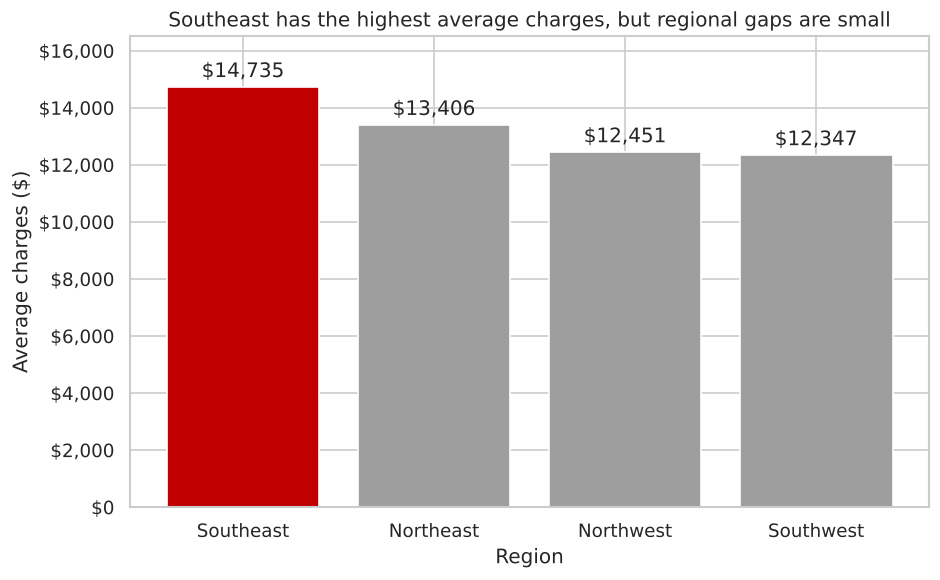

In [13]:
# Bar chart: average charges by region (sorted, highest highlighted)
avg_region = df.groupby('region', observed=True)['charges'].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(avg_region.index.astype(str).str.title(), avg_region.values,
              color=[RED] + [GREY] * (len(avg_region) - 1))
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in avg_region.values], padding=3)
ax.set_ylim(0, avg_region.max() * 1.12)   # leave room for the labels
ax.yaxis.set_major_formatter(money)
ax.set_xlabel('Region')
ax.set_ylabel('Average charges ($)')
ax.set_title('Southeast has the highest average charges, but regional gaps are small')
plt.tight_layout()
plt.show()

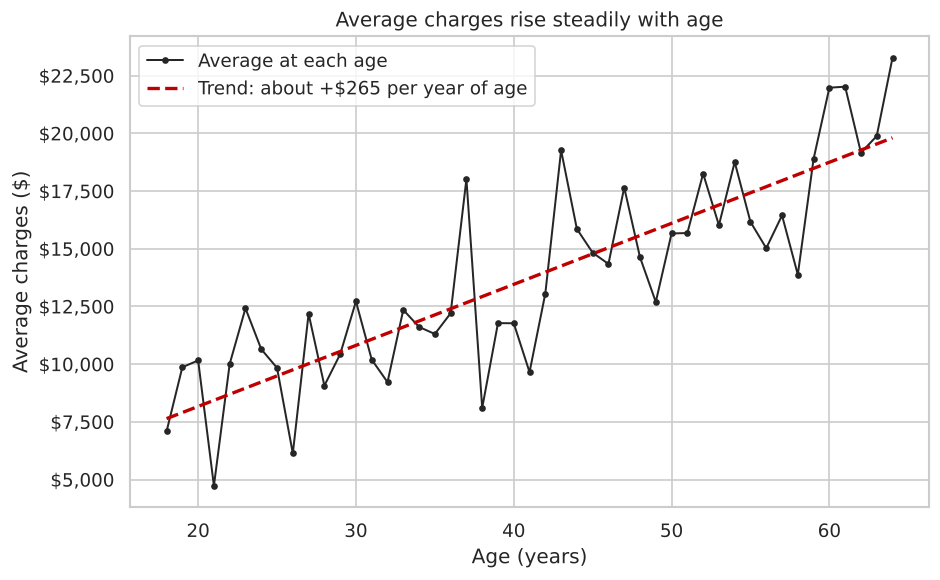

In [14]:
# Line chart: average charges by age (every age from 18 to 64)
avg_age = df.groupby('age')['charges'].mean()
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(avg_age.index, avg_age.values, color=DARK, marker='o', markersize=3, linewidth=1.2,
        label='Average at each age')
# Straight-line trend to make the overall direction clear
slope, intercept = np.polyfit(avg_age.index, avg_age.values, 1)
ax.plot(avg_age.index, slope * avg_age.index + intercept, color=RED, linestyle='--',
        linewidth=2, label=f'Trend: about +${slope:,.0f} per year of age')
ax.legend(loc='upper left')
ax.yaxis.set_major_formatter(money)
ax.set_xlabel('Age (years)')
ax.set_ylabel('Average charges ($)')
ax.set_title('Average charges rise steadily with age')
plt.tight_layout()
plt.show()

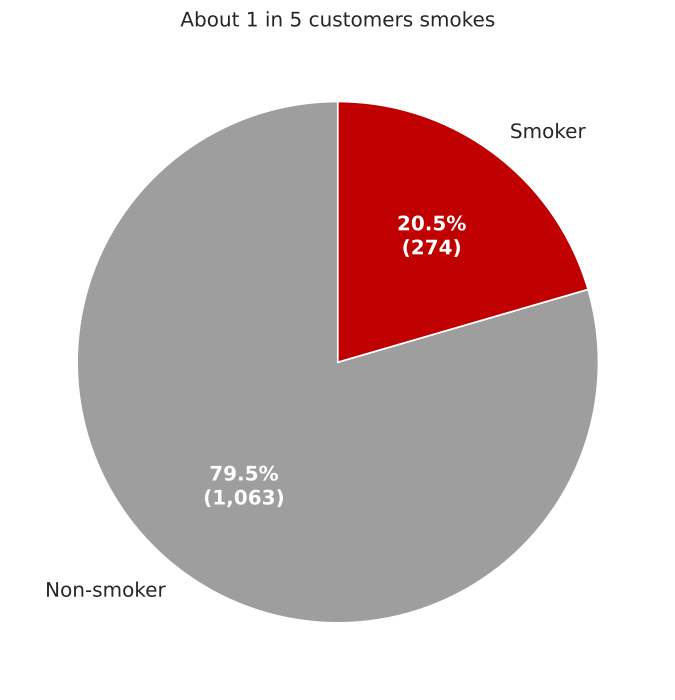

In [15]:
# Pie chart: smokers vs non-smokers
counts = df['smoker'].value_counts().reindex(['no', 'yes'])
fig, ax = plt.subplots(figsize=(6, 6))
wedges, labels, pcts = ax.pie(counts.values, labels=['Non-smoker', 'Smoker'], colors=[GREY, RED],
       autopct=lambda p: f'{p:.1f}%\n({p * len(df) / 100:,.0f})', startangle=90,
       wedgeprops={'edgecolor': 'white'}, textprops={'fontsize': 12})
for t in pcts:
    t.set_color('white'); t.set_fontweight('bold')
ax.set_title('About 1 in 5 customers smokes')
plt.tight_layout()
plt.show()

**Step 6: Visualisation with Seaborn**



*   Create histogram (charges),
*   Boxplot (smoker vs non-smoker),
*   Scatter plot (BMI vs  charges),
*   Heatmap (correlations).

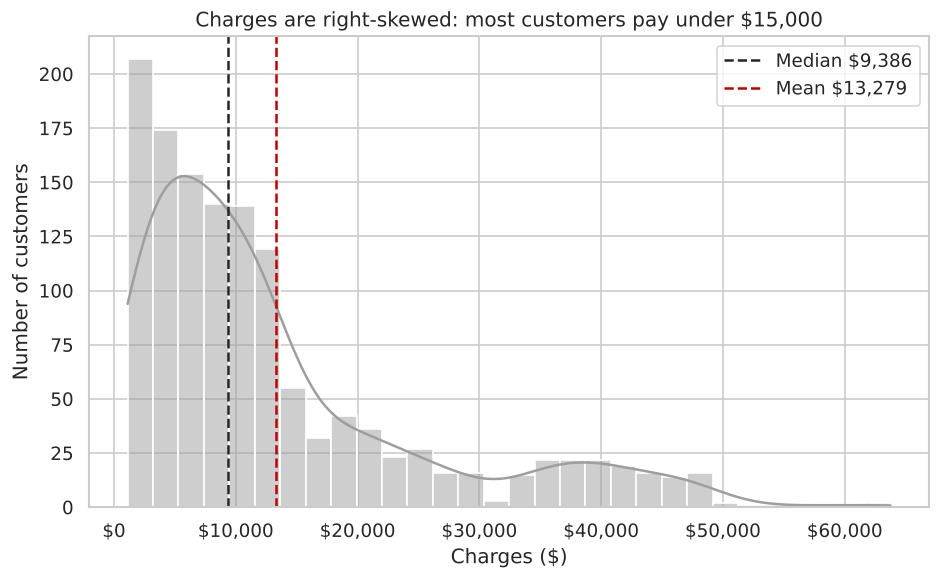

In [16]:
# Histogram: distribution of charges, with mean and median marked
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df['charges'], bins=30, kde=True, color=GREY, ax=ax)
ax.axvline(df['charges'].median(), color=DARK, linestyle='--', label=f"Median ${df['charges'].median():,.0f}")
ax.axvline(df['charges'].mean(), color=RED, linestyle='--', label=f"Mean ${df['charges'].mean():,.0f}")
ax.xaxis.set_major_formatter(money)
ax.set_xlabel('Charges ($)')
ax.set_ylabel('Number of customers')
ax.set_title('Charges are right-skewed: most customers pay under $15,000')
ax.legend()
plt.tight_layout()
plt.show()

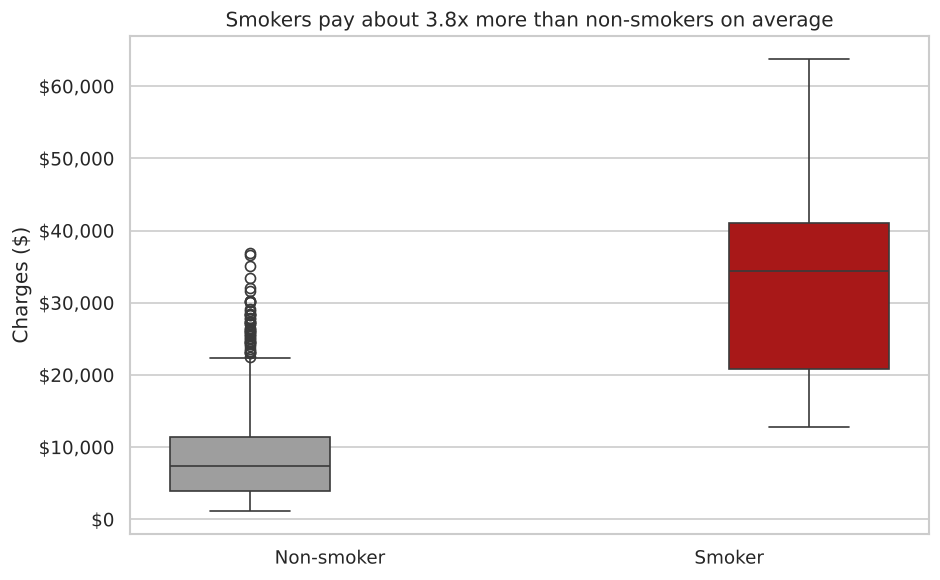

In [17]:
# Boxplot: charges for smokers vs non-smokers
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x='smoker', y='charges', order=['no', 'yes'], hue='smoker',
            hue_order=['no', 'yes'], palette=[GREY, RED], legend=False, ax=ax)
ax.set_xticks([0, 1], ['Non-smoker', 'Smoker'])
ax.yaxis.set_major_formatter(money)
ax.set_xlabel('')
ax.set_ylabel('Charges ($)')
ax.set_title(f'Smokers pay about {ratio:.1f}x more than non-smokers on average')
plt.tight_layout()
plt.show()

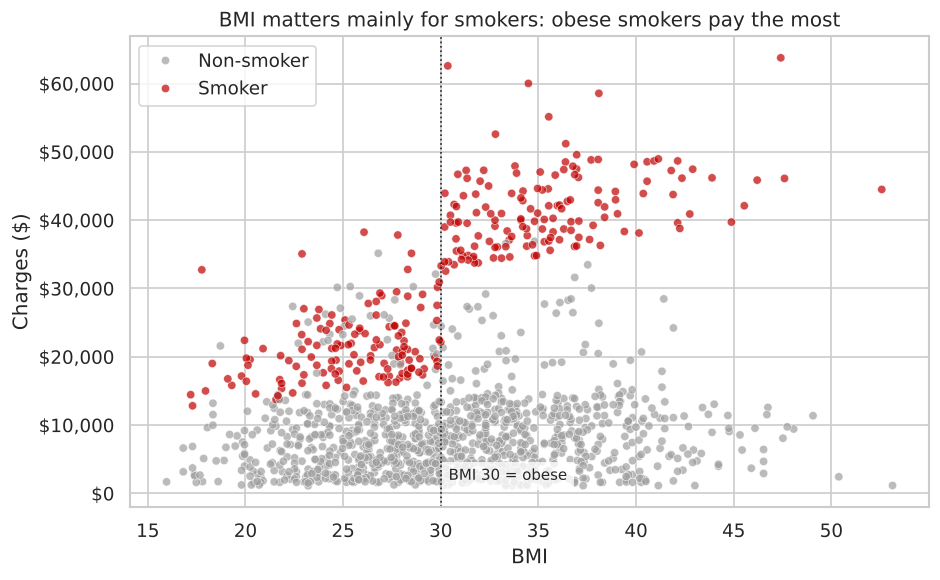

In [18]:
# Scatter plot: BMI vs charges, coloured by smoking status
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', hue_order=['no', 'yes'],
                palette=[GREY, RED], alpha=0.7, s=25, ax=ax)
ax.axvline(30, color=DARK, linestyle=':', linewidth=1)
ax.text(30.4, 2000, 'BMI 30 = obese', fontsize=9, color=DARK,
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
ax.yaxis.set_major_formatter(money)
ax.set_xlabel('BMI')
ax.set_ylabel('Charges ($)')
ax.set_title('BMI matters mainly for smokers: obese smokers pay the most')
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['Non-smoker', 'Smoker'], loc='upper left')
plt.tight_layout()
plt.show()

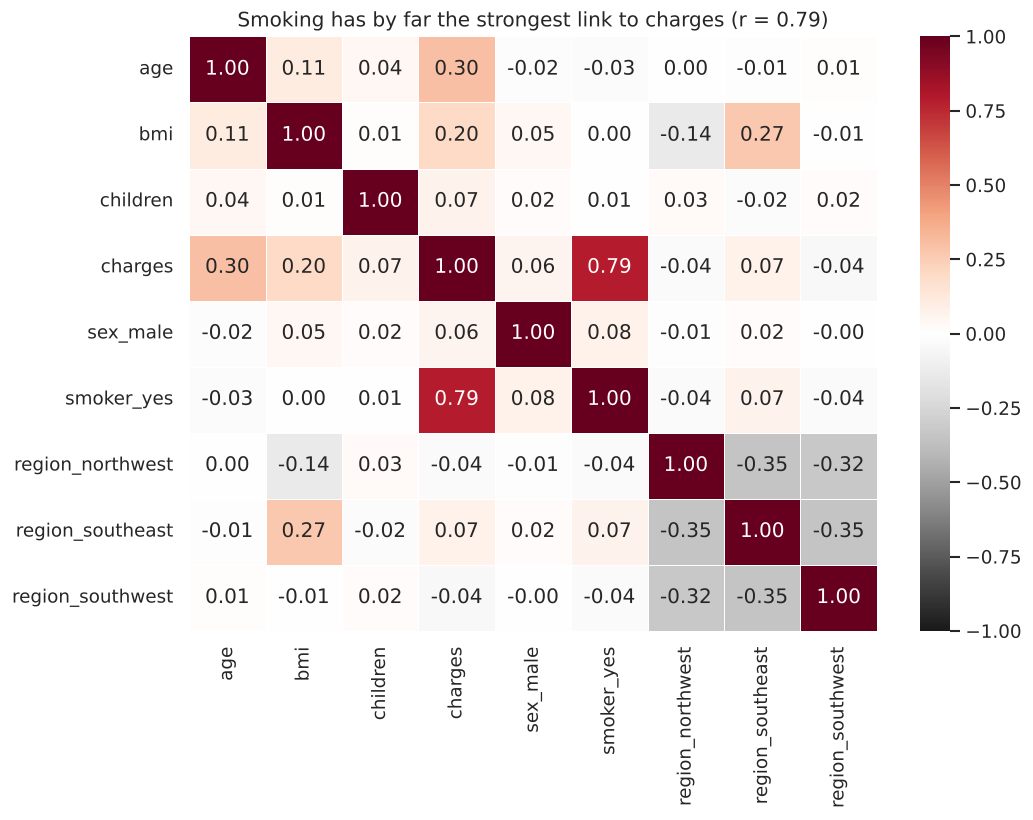

Correlation with charges, strongest first:
smoker_yes          0.79
age                 0.30
bmi                 0.20
region_southeast    0.07
children            0.07
sex_male            0.06
region_southwest   -0.04
region_northwest   -0.04
Name: charges, dtype: float64


In [19]:
# Heatmap: correlations (categorical columns one-hot encoded)
df_encoded = pd.get_dummies(df.drop(columns=['bmi_category', 'age_group']),
                            columns=['sex', 'smoker', 'region'], drop_first=True, dtype=int)
corr = df_encoded.corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdGy_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, ax=ax)
ax.set_title('Smoking has by far the strongest link to charges (r = 0.79)')
plt.tight_layout()
plt.show()

print("Correlation with charges, strongest first:")
print(corr['charges'].drop('charges').sort_values(key=abs, ascending=False).round(2))

**Step 7: Business Insights & Reflection**

**Summary of findings**

- **Smokers vs non-smokers:** Smoking is the biggest driver of charges. The 20.5% of customers who smoke average **\$32,050**, against **\$8,441** for non-smokers (about **3.8×**). Smoking has the strongest correlation with charges (**r = 0.79**), and in the boxplot the two groups barely overlap.
- **BMI effect:** BMI's overall correlation with charges is weak to moderate (**r = 0.20**), but the scatter plot shows that the effect is concentrated in smokers. Smokers with BMI 30+ average **\$41,558**, compared with **\$21,363** for smokers below 30. Among non-smokers BMI makes little difference.
- **Age impact:** Charges rise steadily with age (**r = 0.30**). The average goes from **\$9,688** (18–34) to **\$13,744** (35–49) and **\$17,903** (50–64). Among non-smokers, average charges more than triple between the 18–29 and 60–64 age bands.
- **Regional differences:** These are small. Averages range from **\$12,347** (Southwest) to **\$14,735** (Southeast), and every region-to-charges correlation is below 0.07. The Southeast's higher average comes with more smokers (25%) and a higher average BMI (33.4), so region itself is unlikely to be a driver.
- **Other factors:** Sex (r = 0.06) and number of children (r = 0.07) have little effect.

*Note: correlation shows association, not cause. This dataset can't prove that smoking or BMI cause higher charges, but the pattern is consistent with known health risks.*

**Reflection question:**


If you were advising the company,

1. Which three factors are the strongest drivers of charges and
2. Why?

**Answer:**

1. **Smoking status (r = 0.79):** Smokers pay about 3.8× more on average. Smoking causes chronic conditions (heart and lung disease, cancer) that are expensive to treat.
2. **Age (r = 0.30):** Charges rise with almost every year of age, from about \$9.7k for 18–34s to \$17.9k for 50–64s, because health problems become more common as people get older.
3. **BMI (r = 0.20), especially combined with smoking:** Obese smokers average \$41.6k, the highest-cost group in the data. A high BMI is linked to diabetes, heart disease and joint problems.

Sex, region and number of children have only weak links to charges (all |r| < 0.07).

**Business recommendations**

1. **Make smoking status the main pricing factor, and verify it.** Smoking is the strongest driver of charges, so it should carry the most weight in premiums. The company should also check declarations (e.g. with a medical questionnaire or cotinine test) to stop customers under-reporting.
2. **Target stop-smoking and weight-management programmes at smokers with BMI 30+.** This group averages about \$41.6k a year. Helping even a small share of them quit or lose weight could cut claims much more than a programme aimed at everyone.
3. **Use age bands in pricing, and don't price by region or gender.** Age has a steady, predictable effect. Regional and gender gaps are small and largely explained by smoking and BMI, so pricing on smoking and BMI directly is fairer and more accurate.

In [20]:
# Save the cleaned dataset (with the new columns) to a CSV file
out_path = os.path.join(DATA_DIR, 'cleaned_insurance.csv')
df.to_csv(out_path, index=False)
print(f"Saved {out_path} with {df.shape[0]:,} rows and {df.shape[1]} columns")

Saved ../data/cleaned_insurance.csv with 1,337 rows and 9 columns
